# Session 5 – Random Forest Classifier: Titanic Survival

**Goal:** Train a Random Forest on the same Titanic passenger dataset used in the Decision Tree exercise, so you can compare both models fairly.

This practical follows the bootstrap sampling (bagging), random feature selection, multiple trees, majority voting, Out-of-Bag (OOB) evaluation, feature importance and hyperparameter experiments.

Target: `Survived` (0 = did not survive, 1 = survived).


## 1. Load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/navaneeth20/Aadh/master/Data/Titanic.csv"
df = pd.read_csv(url)
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Explore the data

In [2]:
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
target = "Survived"

display(df[features + [target]].isna().sum().to_frame("missing_count"))
display(df[target].value_counts().rename(index={0:"Did not survive", 1:"Survived"}).to_frame("passengers"))
print("Overall survival rate: {:.1%}".format(df[target].mean()))


,missing_count
Pclass,0
Sex,0
Age,177
SibSp,0
Parch,0
Fare,0
Embarked,2
Survived,0


,passengers
Survived,
Did not survive,549
Survived,342


Overall survival rate: 38.4%


## 3. Prepare features and split the data
Random Forest does not require feature scaling. Missing values are imputed and categorical variables are one-hot encoded.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

X, y = df[features].copy(), df[target].copy()
numeric = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
categorical = ["Sex", "Embarked"]

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))


Training rows: 712 | Test rows: 179


## 4. Bootstrap sampling (Bagging)

For each tree, Random Forest samples N rows **with replacement** from N training rows. Some rows repeat; others are left out. On average, about 63.2% of rows are unique in a bootstrap sample and about 36.8% are Out-of-Bag (OOB) for that tree.

In [4]:
rng = np.random.default_rng(42)
n = len(X_train)
boot_idx = rng.choice(np.arange(n), size=n, replace=True)
unique_idx = np.unique(boot_idx)
oob_idx = np.setdiff1d(np.arange(n), unique_idx)

print("Original training rows:", n)
print("Rows drawn (including repeats):", len(boot_idx))
print("Unique rows selected:", len(unique_idx))
print("OOB rows:", len(oob_idx))
print("Unique selected: {:.1%} | OOB: {:.1%}".format(len(unique_idx)/n, len(oob_idx)/n))


Original training rows: 712
Rows drawn (including repeats): 712
Unique rows selected: 446
OOB rows: 266
Unique selected: 62.6% | OOB: 37.4%


## 5. Train the Random Forest

`n_estimators` is the number of trees. `max_features="sqrt"` means each split considers a random subset of features (approximately the square root of the total feature count). OOB scoring estimates performance from training rows left out of each tree's bootstrap sample.

In [5]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300, criterion="gini", max_features="sqrt",
        max_depth=None, min_samples_split=2, min_samples_leaf=1,
        bootstrap=True, oob_score=True, random_state=42, n_jobs=-1
    ))
])
rf_model.fit(X_train, y_train)
rf = rf_model.named_steps["classifier"]
print("Trees:", len(rf.estimators_))
print("OOB score:", round(rf.oob_score_, 4))


Trees: 300
OOB score: 0.809


## 6. Inspect one tree inside the forest
A forest may contain hundreds of trees. Inspecting one tree helps explain an individual learner, but the final prediction comes from the whole ensemble.

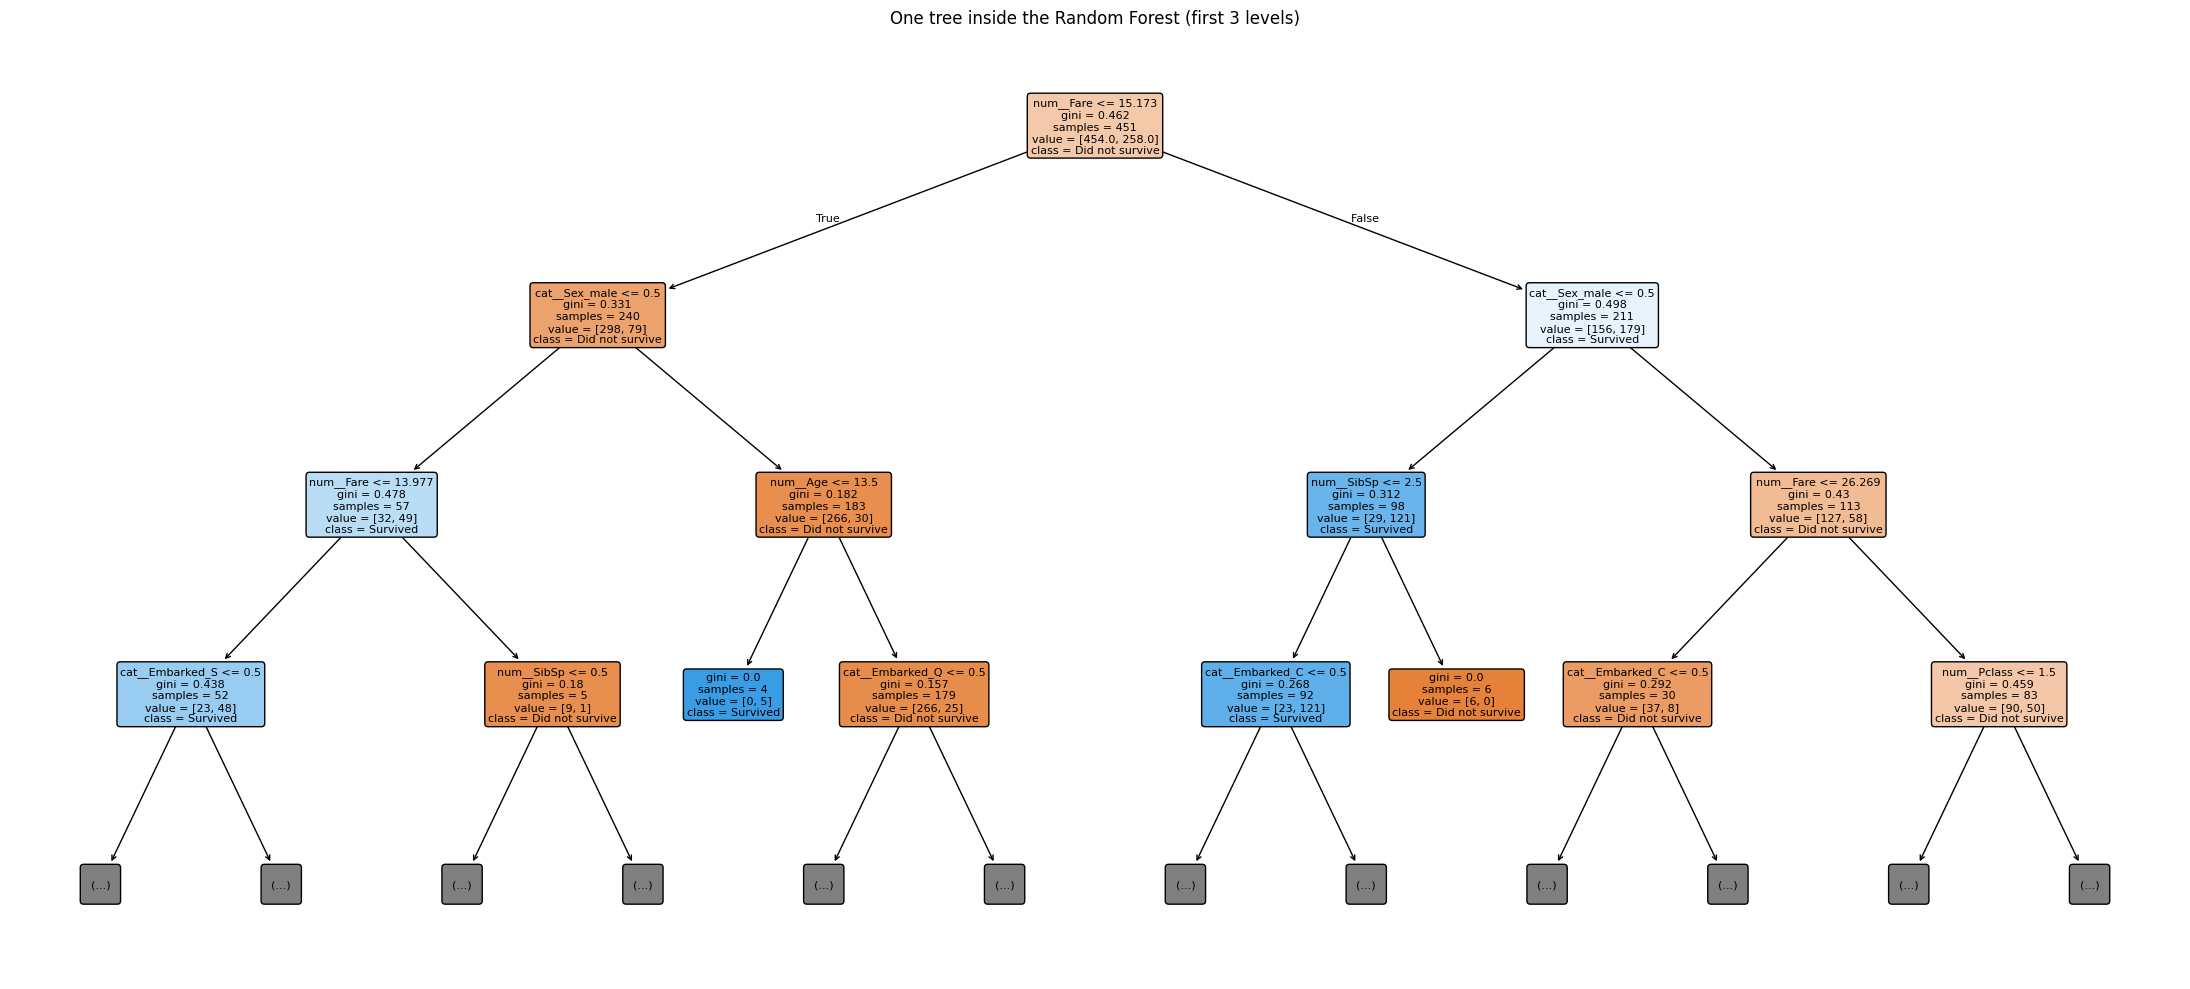

In [6]:
from sklearn.tree import plot_tree

feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()
plt.figure(figsize=(22, 10))
plot_tree(rf.estimators_[0], feature_names=feature_names,
          class_names=["Did not survive", "Survived"], filled=True,
          rounded=True, max_depth=3, fontsize=8)
plt.title("One tree inside the Random Forest (first 3 levels)")
plt.tight_layout()
plt.show()


In [9]:
votes = ["Survived", "Not Survived", "Survived", "Survived", "Not Survived"]
vote_counts = pd.Series(votes).value_counts()
for i, vote in enumerate(votes, start=1):
    print(f"Tree {i}: {vote}")
display(vote_counts.to_frame("votes"))
print("Final prediction:", vote_counts.idxmax())


Tree 1: Survived
Tree 2: Not Survived
Tree 3: Survived
Tree 4: Survived
Tree 5: Not Survived


,votes
Survived,3
Not Survived,2


Final prediction: Survived


## 8. Predict an individual Titanic passenger

In [10]:
passenger = pd.DataFrame([{
    "Pclass": 3, "Sex": "male", "Age": 22, "SibSp": 1,
    "Parch": 0, "Fare": 7.25, "Embarked": "S"
}])
pred = rf_model.predict(passenger)[0]
proba = rf_model.predict_proba(passenger)[0]
print("Prediction:", "Survived" if pred == 1 else "Did not survive")
print("P(did not survive): {:.1%}".format(proba[0]))
print("P(survived): {:.1%}".format(proba[1]))


Prediction: Did not survive
P(did not survive): 86.3%
P(survived): 13.7%


## 9. Evaluate on the held-out test set

Test accuracy: 0.821
                 precision    recall  f1-score   support

Did not survive       0.82      0.90      0.86       110
       Survived       0.81      0.70      0.75        69

       accuracy                           0.82       179
      macro avg       0.82      0.80      0.81       179
   weighted avg       0.82      0.82      0.82       179



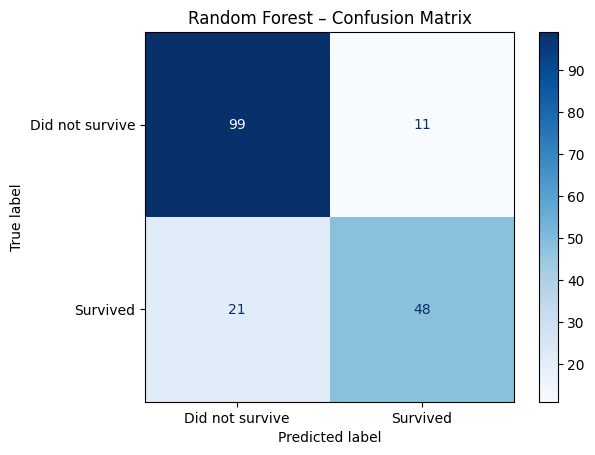

In [11]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

y_pred_rf = rf_model.predict(X_test)
print("Test accuracy: {:.3f}".format(accuracy_score(y_test, y_pred_rf)))
print(classification_report(y_test, y_pred_rf,
      target_names=["Did not survive", "Survived"]))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_rf, display_labels=["Did not survive", "Survived"], cmap="Blues"
)
plt.title("Random Forest – Confusion Matrix")
plt.show()


## 10. Out-of-Bag (OOB) evaluation

For each training row, OOB prediction aggregates votes only from trees whose bootstrap sample did not contain that row. OOB score is a useful internal estimate; it does not replace final evaluation on a held-out test set.

In [12]:
print("OOB score on training data: {:.3f}".format(rf.oob_score_))
print("Held-out test accuracy: {:.3f}".format(accuracy_score(y_test, y_pred_rf)))


OOB score on training data: 0.809
Held-out test accuracy: 0.821


## 11. Feature importance

Importance is based on the total impurity reduction attributed to each encoded feature across the forest. It is useful for exploration, but it does not prove causation.

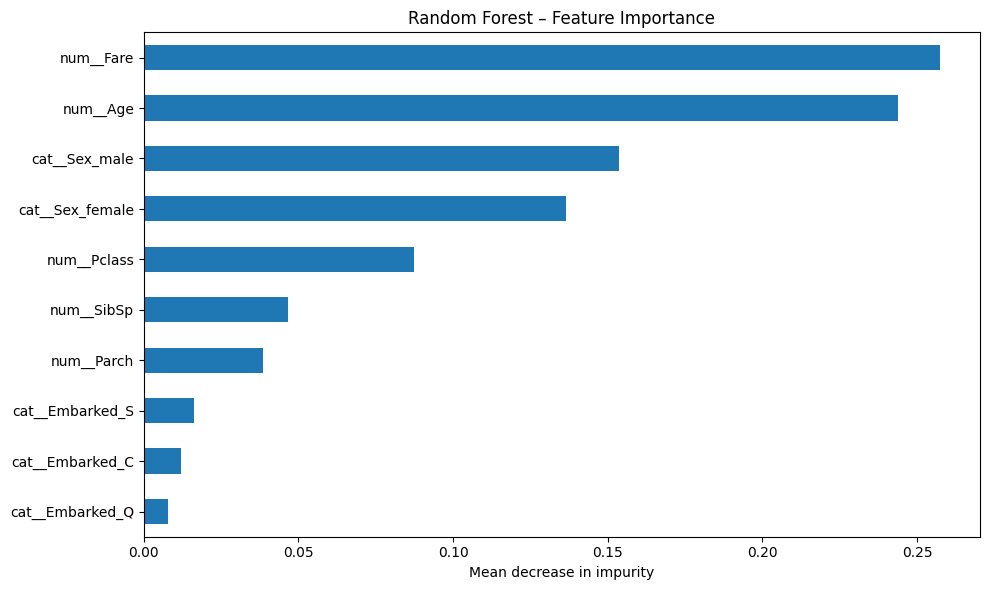

,importance
num__Fare,0.257490
num__Age,0.243869
cat__Sex_male,0.153717
cat__Sex_female,0.136457
num__Pclass,0.087248
num__SibSp,0.046531
num__Parch,0.038527
cat__Embarked_S,0.016330
cat__Embarked_C,0.012098
cat__Embarked_Q,0.007733


In [13]:
importance = pd.Series(rf.feature_importances_, index=feature_names).sort_values()
plt.figure(figsize=(10, 6))
importance.plot(kind="barh")
plt.xlabel("Mean decrease in impurity")
plt.title("Random Forest – Feature Importance")
plt.tight_layout()
plt.show()
display(importance.sort_values(ascending=False).to_frame("importance"))


## 12. Compare Decision Tree vs Random Forest
Use the same preprocessing and same train/test split for a fair comparison.

In [14]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import precision_score, recall_score, f1_score

dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini", max_depth=4, min_samples_leaf=10, random_state=42
    ))
])
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

comparison = pd.DataFrame([
    {"Model":"Decision Tree", "Accuracy":accuracy_score(y_test,y_pred_dt),
     "Precision":precision_score(y_test,y_pred_dt), "Recall":recall_score(y_test,y_pred_dt),
     "F1":f1_score(y_test,y_pred_dt)},
    {"Model":"Random Forest", "Accuracy":accuracy_score(y_test,y_pred_rf),
     "Precision":precision_score(y_test,y_pred_rf), "Recall":recall_score(y_test,y_pred_rf),
     "F1":f1_score(y_test,y_pred_rf)}
])
display(comparison.round(3))


,Model,Accuracy,Precision,Recall,F1
0,Decision Tree,0.777,0.809,0.551,0.655
1,Random Forest,0.821,0.814,0.696,0.750


## 13. Hyperparameter experiment

- `n_estimators`: number of trees.
- `max_features`: number of candidate features at each split.
- `max_depth`: maximum depth of each tree.
- `min_samples_leaf`: minimum records in a leaf.

Observe whether test performance plateaus as the number of trees increases, and whether deeper trees create a train/test performance gap.

In [15]:
from sklearn.base import clone

results = []
for n_trees in [50, 100, 300]:
    for depth in [4, 8, None]:
        experiment = Pipeline([
            ("preprocessor", clone(preprocessor)),
            ("classifier", RandomForestClassifier(
                n_estimators=n_trees, max_features="sqrt", max_depth=depth,
                min_samples_leaf=2, bootstrap=True, random_state=42, n_jobs=-1
            ))
        ])
        experiment.fit(X_train, y_train)
        results.append({
            "n_estimators": n_trees, "max_depth": str(depth),
            "train_accuracy": experiment.score(X_train, y_train),
            "test_accuracy": experiment.score(X_test, y_test)
        })
display(pd.DataFrame(results).sort_values("test_accuracy", ascending=False))


,n_estimators,max_depth,train_accuracy,test_accuracy
6,300,4,0.842697,0.810056
5,100,None,0.908708,0.810056
0,50,4,0.838483,0.804469
4,100,8,0.897472,0.804469
3,100,4,0.842697,0.804469
7,300,8,0.900281,0.804469
8,300,None,0.912921,0.804469
2,50,None,0.911517,0.798883
1,50,8,0.898876,0.793296


## 14. Classroom discussion and challenge

1. Why does each tree receive a different bootstrap sample?
2. Why can the same row appear more than once in a bootstrap sample?
3. What does the 63% unique / 37% OOB idea mean?
4. Why select only a random subset of features at each split?
5. How does majority voting work with 100 trees?
6. What is the difference between OOB score and test accuracy?
7. Why is a forest harder to interpret than one tree?
8. Does Random Forest always outperform a Decision Tree?

**Hands-on challenge:** Change `n_estimators`, `max_features`, `max_depth` and `min_samples_leaf`. Compare test metrics, OOB score and training time. Discuss the trade-off between performance, stability, interpretability and compute cost.

## Answers for Classroom Discussion

### 1. Why does each tree receive a different bootstrap sample?
To introduce diversity among individual trees. If every tree trained on the identical dataset, they would all make highly correlated decisions and yield similar structures. By training on different bootstrap samples, each tree learns slightly different patterns, which reduces the overall variance when their predictions are averaged.

### 2. Why can the same row appear more than once in a bootstrap sample?
Bootstrap sampling is performed **with replacement**. This means after a row is randomly selected, it is placed back into the pool and can be selected again in the next draw. This statistical method helps simulate drawing samples from the true underlying population distribution.

### 3. What does the 63% unique / 37% OOB idea mean?
For a training set of size $N$, the probability of a specific row *not* being picked in a single draw is $1 - 1/N$. After $N$ random draws with replacement, the probability that a row is never picked is:
$$\lim_{N \to \infty} \left(1 - \frac{1}{N}\right)^N = \frac{1}{e} \approx 0.368 \text{ (or 36.8\%)}$$
Thus, approximately 36.8% of the rows are left out (Out-of-Bag, or OOB), while the remaining ~63.2% are unique rows included in the bootstrap sample.

### 4. Why select only a random subset of features at each split?
This is called **Feature Bagging** (controlled by `max_features`). If there is one extremely strong predictive feature (e.g., `Sex` for Titanic survival), almost every single tree would choose that feature for its root split, making the trees highly correlated. Restricting the candidate features at each split forces some trees to split on other useful features (like `Pclass` or `Fare`), promoting diversity and improving the ensemble's overall robustness.

### 5. How does majority voting work with 100 trees?
When an unseen passenger is passed to the ensemble, each of the 100 trees outputs its own individual prediction (e.g., 65 trees predict "Survived", 35 predict "Did not survive"). The Random Forest aggregates these votes, and the class with the most votes (in this case, "Survived") becomes the final predicted class.

### 6. What is the difference between OOB score and test accuracy?
* **OOB Score:** Calculated strictly during training. For each training instance, the model aggregates predictions only from those individual trees that did *not* have that instance in their bootstrap sample. It serves as an internal validation score.
* **Test Accuracy:** Evaluated on an entirely separate, held-out test dataset (`X_test`) that was never seen by any tree during any stage of model building.

### 7. Why is a forest harder to interpret than one tree?
A single decision tree can be plotted and traced line-by-line using a sequence of simple IF-ELSE decisions. A Random Forest consists of hundreds of different trees, each with different structures and feature paths, making it virtually impossible for a human to trace the exact pathway of a single final prediction.

### 8. Does Random Forest always outperform a Decision Tree?
Not always, but it usually does when dealing with complex, high-variance datasets. A Single Decision Tree can easily overfit the training data. However, if the relationship in the data is very simple and linear, or if the dataset is extremely small, a carefully pruned Decision Tree might match or occasionally outperform a Random Forest while being much faster and easier to interpret.